In [ ]:
import pandas as pd
import numpy as np
import time
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, confusion_matrix

df = pd.read_csv('data/processed_reviews.csv')

# Sprawdź równowagę klas
print("Dataset balance:\n", df['label'].value_counts())

X = df['full_text']
y = df['label']

# 80% trening, 20% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

Dataset balance:
 label
1    29837
2    29837
0    29837
Name: count, dtype: int64


In [ ]:
# Eksperyment: Usunięcie filtra słów stop, aby sprawdzić, czy łączniki pomagają modelowi
tfidf = TfidfVectorizer(
    max_features=30000, 
    stop_words=None,       # Tym razem zachowujemy WSZYSTKIE słowa
    ngram_range=(1, 3),    # Zachowujemy trigramy
    lowercase=True,
    min_df=3
)

print("Vectorizing text with trigrams...")
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print(f"Total features (unigrams, bigrams, trigrams): {X_train_tfidf.shape[1]}")

Vectorizing text with trigrams...
Total features (unigrams, bigrams, trigrams): 30000


In [43]:
print(f"Shape of training matrix: {X_train_tfidf.shape}")

Shape of training matrix: (71608, 30000)


In [ ]:
# LinearSVC z niższym parametrem C (0.3) dla lepszej generalizacji
# Zwiększenie max_iter, aby zapewnić zbieżność modelu z większą liczbą cech
svm = LinearSVC(
    C=0.3, 
    random_state=42, 
    max_iter=3000
)

# Pomiar czasu treningu dla oceny wydajności
start_time = time.time()
svm.fit(X_train_tfidf, y_train)
training_duration = time.time() - start_time

print(f"Training completed in: {training_duration:.2f} seconds")

# Ocena modelu na zbiorze testowym
y_pred = svm.predict(X_test_tfidf)

# Generowanie raportu klasyfikacji
from sklearn.metrics import classification_report
print("\nSVM Classification Report (Experimental):")
print(classification_report(y_test, y_pred, target_names=['Negative', 'Neutral', 'Positive']))

Training completed in: 8.62 seconds

SVM Classification Report (Experimental):
              precision    recall  f1-score   support

    Negative       0.77      0.77      0.77      5967
     Neutral       0.69      0.68      0.68      5968
    Positive       0.84      0.86      0.85      5968

    accuracy                           0.77     17903
   macro avg       0.77      0.77      0.77     17903
weighted avg       0.77      0.77      0.77     17903



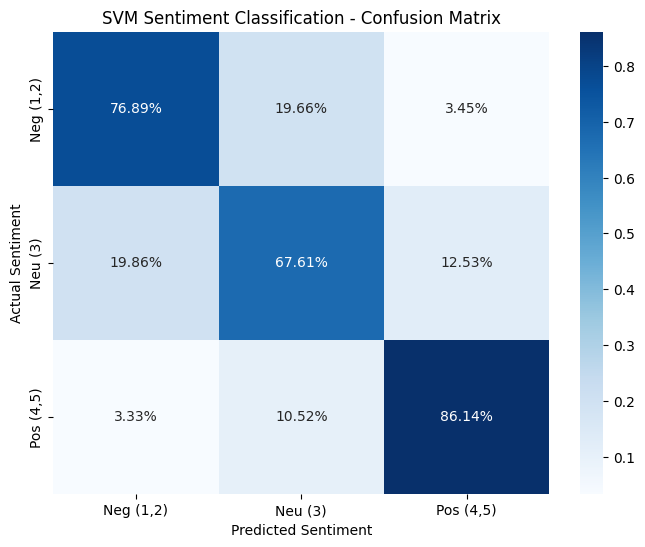

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)
cm_percent = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] # Percentages

# Profesjonalne wyświetlanie
plt.figure(figsize=(8, 6))
sns.heatmap(cm_percent, annot=True, fmt='.2%', cmap='Blues',
            xticklabels=['Neg (1,2)', 'Neu (3)', 'Pos (4,5)'],
            yticklabels=['Neg (1,2)', 'Neu (3)', 'Pos (4,5)'])
plt.ylabel('Actual Sentiment')
plt.xlabel('Predicted Sentiment')
plt.title('SVM Sentiment Classification - Confusion Matrix')
plt.show()

In [ ]:
# Tworzymy DataFrame z wynikami testowymi
results_df = pd.DataFrame({
    'text': X_test,
    'actual': y_test,
    'predicted': y_pred
})

# Wyciągamy błędy (np. model myślał, że to Neutral, a był Negatyw)
errors = results_df[results_df['actual'] != results_df['predicted']]

print(f"Liczba błędnych predykcji: {len(errors)}")

# Wyświetlmy 5 przykładów, gdzie model najbardziej się pomylił
extreme_errors = errors[(errors['actual'] == 0) & (errors['predicted'] == 2)]

print("\nPrzykłady skrajnych pomyłek (Miał być Negatyw, jest Pozytyw):")
for i, row in extreme_errors.head(5).iterrows():
    print(f"--- TEXT: {row['text'][:200]}...") # pierwsze 200 znaków
    print(f"--- ACTUAL: {row['actual']} | PREDICTED: {row['predicted']}\n")

Liczba błędnych predykcji: 4139

Przykłady skrajnych pomyłek (Miał być Negatyw, jest Pozytyw):
--- TEXT: Serious health food If you're out for sheer health benefits without taste and without desirable texture, this one's for you.  I did not expect much out of it except health benefits, so I wasn't surpri...
--- ACTUAL: 0 | PREDICTED: 2

--- TEXT: frenchs horseradish mustard first of all I like Frenchs regular and deli mustards but when it comes to horseradish mustard they really havent got a clue there horseradish mustard sucks its not hot at ...
--- ACTUAL: 0 | PREDICTED: 2

--- TEXT: Stale cookies If you like stale cookies, you will love these expensive cookies from Tate.  My daughter sent me three packs for Father's Day.  She is a loving daughter and would not try to fool me into...
--- ACTUAL: 0 | PREDICTED: 2

--- TEXT: Great product....don't order on amazon The chocolate is just as delicious as could be expected. The wrap is easy to remove and re wrap again. The kisses in the ins